# Artificial Intelligence – Assignment 1
## Customer Churn Prediction Using Machine Learning
**Course:** Artificial Intelligence  
**Dataset:** Telco Customer Churn

This version completes the same required ML pipeline with a different feature-engineering step and a different train/test seed. It adds `AvgMonthlySpend` and compares Logistic Regression with Decision Tree.

## 1. Import Libraries and Load Dataset

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

DATA_FILE="WA_Fn-UseC_-Telco-Customer-Churn(1).csv"
if not os.path.exists(DATA_FILE):
    from google.colab import files
    uploaded=files.upload()
    DATA_FILE=next(iter(uploaded.keys()))
df=pd.read_csv(DATA_FILE)
print("Dataset shape:",df.shape)


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset shape: (7043, 21)


## 2. Data Understanding

In [2]:
display(df.head())
print("Columns:",df.columns.tolist())
display(df.dtypes.to_frame("Data Type"))
display(df.describe(include="all").T)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,Data Type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Important Columns
`customerID` identifies a customer; `tenure` gives months with the company; `Contract` describes contract type; `MonthlyCharges` is the monthly bill; `TotalCharges` is cumulative billing; `InternetService` describes internet type; `Churn` is the target (Yes/No).

## 3. Data Preprocessing

In [3]:
print("Duplicate rows:",df.duplicated().sum())
print("Missing values before conversion:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("Missing"))
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")
df=df.drop(columns=["customerID"])
print("Missing values after TotalCharges conversion:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("Missing"))


Duplicate rows: 0
Missing values before conversion:


,Missing
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Missing values after TotalCharges conversion:


,Missing
TotalCharges,11
gender,0
Partner,0
SeniorCitizen,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0
OnlineBackup,0


`TotalCharges` is converted to numeric because blank values are stored as text. `customerID` is removed because it is an identifier. Missing values are handled inside the preprocessing pipeline. No duplicate rows are present.

## 4. Exploratory Data Analysis

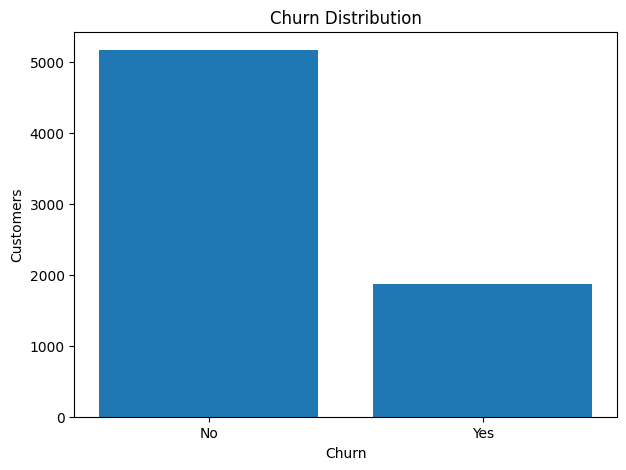

Contract vs churn (%):


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


<Figure size 800x500 with 0 Axes>

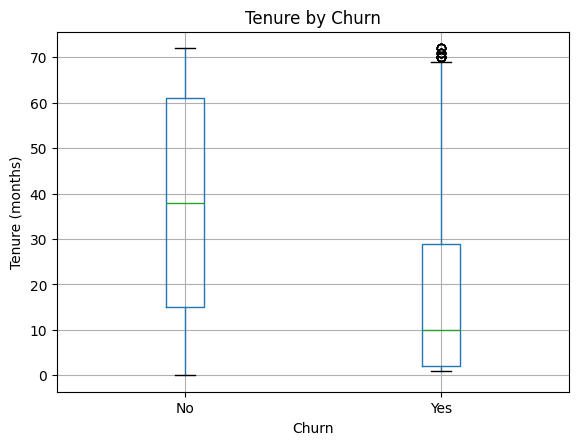

Internet service vs churn (%):


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [4]:
counts=df["Churn"].value_counts()
plt.figure(figsize=(7,5)); plt.bar(counts.index,counts.values)
plt.title("Churn Distribution"); plt.xlabel("Churn"); plt.ylabel("Customers"); plt.show()

print("Contract vs churn (%):")
display((pd.crosstab(df["Contract"],df["Churn"],normalize="index")*100).round(2))

plt.figure(figsize=(8,5))
df.boxplot(column="tenure",by="Churn")
plt.title("Tenure by Churn"); plt.suptitle(""); plt.xlabel("Churn"); plt.ylabel("Tenure (months)"); plt.show()

print("Internet service vs churn (%):")
display((pd.crosstab(df["InternetService"],df["Churn"],normalize="index")*100).round(2))


In [9]:
# 1. Define the Machine Learning Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Combine the preprocessor defined in Feature Engineering and the classifier
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=7))
])

# 2. Fit (Train) the model
print("Training the model...")
model_pipeline.fit(X_train, y_train)

# 3. Predict on Test data and evaluate
y_pred = model_pipeline.predict(X_test)
print("Model Training Complete! Here are the results:\n")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

Training the model...
Model Training Complete! Here are the results:

              precision    recall  f1-score   support

    No Churn       0.92      0.74      0.82      1035
       Churn       0.54      0.82      0.65       374

    accuracy                           0.77      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.82      0.77      0.78      1409



## 5. Feature Engineering and Train/Test Split

In [6]:
df["AvgMonthlySpend"]=df["TotalCharges"]/df["tenure"].replace(0,np.nan)
df["AvgMonthlySpend"]=df["AvgMonthlySpend"].fillna(df["MonthlyCharges"])

X=df.drop(columns=["Churn"])
y=(df["Churn"]=="Yes").astype(int)
categorical_features=X.select_dtypes(include=["object"]).columns.tolist()
numeric_features=X.select_dtypes(exclude=["object"]).columns.tolist()

preprocessor=ColumnTransformer([
    ("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),numeric_features),
    ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical_features)
])
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=7,stratify=y)
print("Training:",X_train.shape," Testing:",X_test.shape)
print("Added feature: AvgMonthlySpend")


Training: (5634, 20)  Testing: (1409, 20)
Added feature: AvgMonthlySpend


## 6. Train Two Classification Models

In [8]:
models={
"Logistic Regression":Pipeline([("preprocessor",preprocessor),("classifier",LogisticRegression(max_iter=1500,class_weight="balanced",random_state=7))]),
"Decision Tree":Pipeline([("preprocessor",preprocessor),("classifier",DecisionTreeClassifier(max_depth=5,min_samples_leaf=8,class_weight="balanced",random_state=7))])
}
trained_models={}; predictions={}; rows=[]
for name,model in models.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    trained_models[name]=model; predictions[name]=pred
    rows.append({"Model":name,"Accuracy":accuracy_score(y_test,pred),"Precision":precision_score(y_test,pred),"Recall":recall_score(y_test,pred),"F1-Score":f1_score(y_test,pred)})
results_df=pd.DataFrame(rows)
display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7658,0.5385,0.8235,0.6512
1,Decision Tree,0.7530,0.5225,0.8075,0.6345


## 7. Model Evaluation

Logistic Regression
              precision    recall  f1-score   support

    No Churn     0.9211    0.7449    0.8237      1035
       Churn     0.5385    0.8235    0.6512       374

    accuracy                         0.7658      1409
   macro avg     0.7298    0.7842    0.7374      1409
weighted avg     0.8196    0.7658    0.7779      1409



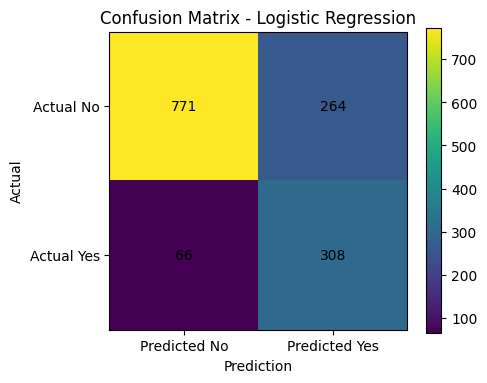

Decision Tree
              precision    recall  f1-score   support

    No Churn     0.9134    0.7333    0.8135      1035
       Churn     0.5225    0.8075    0.6345       374

    accuracy                         0.7530      1409
   macro avg     0.7179    0.7704    0.7240      1409
weighted avg     0.8096    0.7530    0.7660      1409



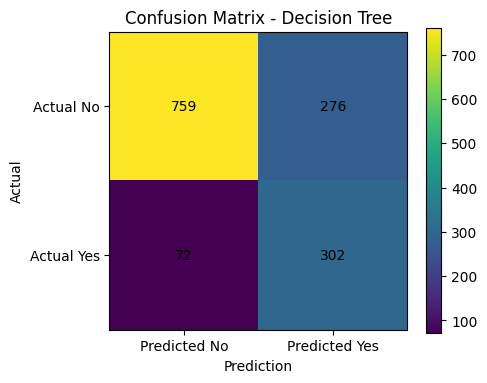

In [10]:
for name,pred in predictions.items():
    print("="*60); print(name); print("="*60)
    print(classification_report(y_test,pred,target_names=["No Churn","Churn"],digits=4))
    cm=confusion_matrix(y_test,pred)
    plt.figure(figsize=(5,4)); plt.imshow(cm,interpolation="nearest")
    plt.title(f"Confusion Matrix - {name}"); plt.colorbar()
    plt.xticks([0,1],["Predicted No","Predicted Yes"]); plt.yticks([0,1],["Actual No","Actual Yes"])
    for i in range(2):
        for j in range(2): plt.text(j,i,cm[i,j],ha="center",va="center")
    plt.xlabel("Prediction"); plt.ylabel("Actual"); plt.tight_layout(); plt.show()


### Metric Meaning
Accuracy = overall correctness. Precision = correctness among predicted churners. Recall = proportion of actual churners detected. F1-score balances precision and recall. The confusion matrix summarizes correct and incorrect class predictions.

## 8. Model Comparison and Final Model

In [11]:
display(results_df.set_index("Model").round(4))
best_model_name=results_df.sort_values(["F1-Score","Accuracy"],ascending=False).iloc[0]["Model"]
final_model=trained_models[best_model_name]
print("Selected final model:",best_model_name)


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.7658,0.5385,0.8235,0.6512
Decision Tree,0.7530,0.5225,0.8075,0.6345


Selected final model: Logistic Regression


## 9. Application / Sample Customer Prediction

In [12]:
sample=pd.DataFrame([
{"gender":"Female","SeniorCitizen":0,"Partner":"Yes","Dependents":"Yes","tenure":48,"PhoneService":"Yes","MultipleLines":"No","InternetService":"DSL","OnlineSecurity":"Yes","OnlineBackup":"Yes","DeviceProtection":"Yes","TechSupport":"Yes","StreamingTV":"Yes","StreamingMovies":"Yes","Contract":"Two year","PaperlessBilling":"No","PaymentMethod":"Bank transfer (automatic)","MonthlyCharges":65.0,"TotalCharges":3100.0},
{"gender":"Male","SeniorCitizen":0,"Partner":"No","Dependents":"No","tenure":2,"PhoneService":"Yes","MultipleLines":"No","InternetService":"Fiber optic","OnlineSecurity":"No","OnlineBackup":"No","DeviceProtection":"No","TechSupport":"No","StreamingTV":"No","StreamingMovies":"No","Contract":"Month-to-month","PaperlessBilling":"Yes","PaymentMethod":"Electronic check","MonthlyCharges":85.0,"TotalCharges":170.0}
])
sample["AvgMonthlySpend"]=sample["TotalCharges"]/sample["tenure"].replace(0,np.nan)
sample["AvgMonthlySpend"]=sample["AvgMonthlySpend"].fillna(sample["MonthlyCharges"])
sample["Prediction"]=np.where(final_model.predict(sample)==1,"Churn","No Churn")
display(sample[["tenure","Contract","InternetService","MonthlyCharges","Prediction"]])


,tenure,Contract,InternetService,MonthlyCharges,Prediction
0,48,Two year,DSL,65.0,No Churn
1,2,Month-to-month,Fiber optic,85.0,Churn


## 10. Final Conclusion
Version 3 completes the required churn prediction workflow. Logistic Regression and Decision Tree are compared using the required classification metrics. The derived AvgMonthlySpend feature provides an additional representation of customer spending. The final model can support retention analysis but should be monitored and retrained for real-world use.